<a href="https://colab.research.google.com/github/MarchianTz/ai-social-media-student-wellbeing/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("AI_SocialMedia_Student_Dataset.csv")
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print(df.columns.tolist())

df.head()

['student_id', 'age', 'gender', 'education_level', 'daily_social_media_hours', 'daily_ai_tool_usage_hours', 'sleep_hours', 'physical_activity_hours', 'mental_health_score', 'physical_health_score']


,student_id,age,gender,education_level,daily_social_media_hours,daily_ai_tool_usage_hours,sleep_hours,physical_activity_hours,mental_health_score,physical_health_score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


In [2]:
df.shape

(16000, 10)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   student_id                 16000 non-null  object 
 1   age                        16000 non-null  int64  
 2   gender                     16000 non-null  object 
 3   education_level            16000 non-null  object 
 4   daily_social_media_hours   16000 non-null  float64
 5   daily_ai_tool_usage_hours  16000 non-null  float64
 6   sleep_hours                16000 non-null  float64
 7   physical_activity_hours    16000 non-null  float64
 8   mental_health_score        16000 non-null  float64
 9   physical_health_score      16000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 1.2+ MB


In [4]:
df.describe()

,age,daily_social_media_hours,daily_ai_tool_usage_hours,sleep_hours,physical_activity_hours,mental_health_score,physical_health_score
count,16000.00000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000,16000.000000
mean,19.03875,4.541791,2.590624,6.545371,1.248359,72.493193,88.020465
std,3.76527,2.403044,1.679376,1.270515,1.038632,9.244818,9.691037
min,13.00000,0.000000,0.000000,2.000000,0.000000,32.560000,48.030000
25%,16.00000,2.840000,1.310000,5.680000,0.310000,66.760000,81.517500
50%,19.00000,4.500000,2.520000,6.540000,1.130000,73.750000,89.455000
75%,22.00000,6.180000,3.750000,7.410000,1.960000,79.550000,97.170000
max,25.00000,14.000000,9.500000,11.150000,5.000000,91.760000,99.980000


In [5]:
df.isna().sum()

,0
student_id,0
age,0
gender,0
education_level,0
daily_social_media_hours,0
daily_ai_tool_usage_hours,0
sleep_hours,0
physical_activity_hours,0
mental_health_score,0
physical_health_score,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df[(df["sleep_hours"] + df["daily_social_media_hours"] + df["physical_activity_hours"]) > 24].shape[0]

0

In [8]:
pd.crosstab(df["education_level"], df["age"])

age,13,14,15,16,17,18,19,20,21,22,23,24,25
education_level,,,,,,,,,,,,,
College,0,0,0,0,0,1238,1246,1200,1206,0,0,0,0
High School,1265,1201,1216,1194,1207,0,0,0,0,0,0,0,0
University,0,0,0,0,0,0,0,0,0,1298,1150,1267,1312


In [9]:
df.groupby("education_level")["age"].agg(["min", "max", "count"])

,min,max,count
education_level,,,
College,18,21,4890
High School,13,17,6083
University,22,25,5027


##Data Inspection Notes
**Dataset size:** 16,000 rows and 10 columns (Synthetic dataset from Kaggle).

**Columns**
- student_id: text identifier, not useful for analysis, so it will be dropped
- age: whole number
- gender, education level: categories(text)
- daily_social_media_hours, daily_ai_tools_usage_hours, sleep_hours, physical_activity_hours: numeric habits (decimals)
-mental_health_score, physical_health_score: numeric outcomes scores(decimals)

**Findings from inspection**
- Missing values: none. All 10 columns have 16,000 non-null entries.
- Data types look correct: 6 decimals columns, 1 whole-number column, 3 text columns.
- Duplicate rows: none found(0).
- Value ranges: no negative values and no hours above 24. Social media usage ranges from 0 to 14 hours (average 4.5), AI tools use from 0 to 9.5 hours (average 2.6), sleep from 2 to 11 hours(average 6.5), and physical activity from 0 to 5 hours(average 1.25).
- Scores: mental health ranges from about 33 to 92(average 72), and physical health from about 48 to 100(average 88).
- Schedule check: no students have more than 24 hours of sleep, social media, and physical activity combined (0 found).
- Age vs education check: ages line up with education levels, but the boundaries are unrealistically clean. For example, high school students are all 13-17, with no overlap into older ages and no early university entrants. Real student populations are messier, which is another sign the data is synthetic.
- Observation: some maximums are round numbers (14 hours of social media, 5 hours of activity), which suggests values were capped when the data was generated.

**Conclusion**

The dataset is already clean, with no missing, duplicate, or impossible values, but it is cleaner than real-world data would be. The only change planned is dropping student_id.

**Main question**

How are social media use, AI tool use, sleep, and physical activity associated with student mental and physical health scores?

In [10]:
df = df.drop(columns=["student_id"])
df.shape

(16000, 9)

## Cleaning Notes
No missing values, duplicates, or impossible values were found, so the only cleaning step was removing student_id, which has no analytical value.

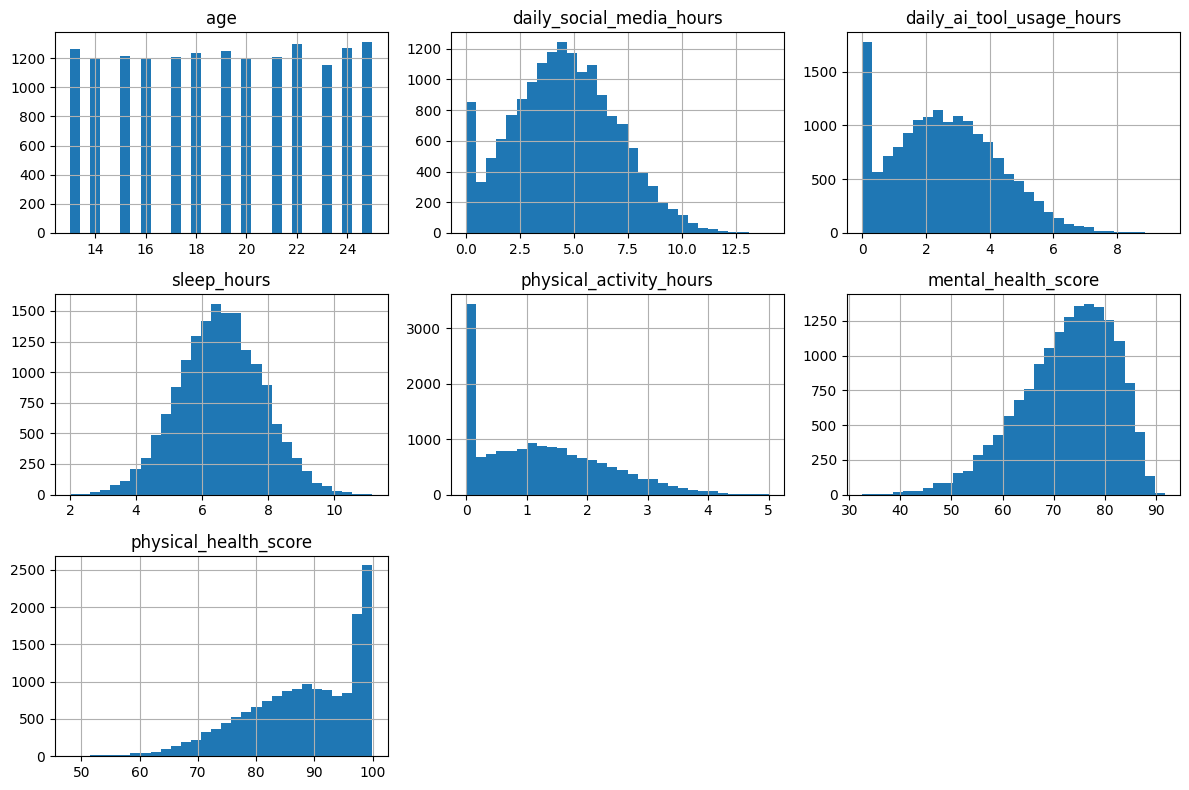

In [11]:
num_cols = df.select_dtypes(include="number").columns
df[num_cols].hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

# Distribution Notes

- **Age** is spread evenly across 13 to 25, so no age group dominates.
- **Social media, AI tool use, and sleep** are roughly bell-shaped. Social media and AI use lean toward lower values with a long tail of heavy users.
- **Spikes at zero:** several columns have a large group of students at exactly 0 hours (about 850 for social media, 1,800 for AI tools, and 3,400 for physical activity). Normal-looking curves with a spike at zero often mean values below zero were clipped to zero when the data was generated, so these zeros may not represent real non-users.
- **Mental health scores** center around 75 to 80, with a tail of lower scores.
- **Physical health scores** pile up near the maximum of 100, which suggests a ceiling was applied. This limits how much variation the models can pick up in that column.
- Overall, the shapes look generated rather than natural, which is consistent with the dataset being synthetic.

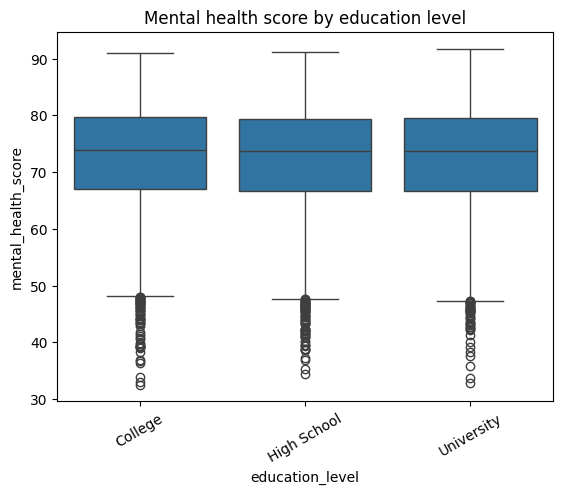

In [12]:
sns.boxplot(data=df, x="education_level", y="mental_health_score")
plt.xticks(rotation=30)
plt.title("Mental health score by education level")
plt.show()

## Mental Health Score by Education Level

Mental health scores are nearly identical across High School, College, and University students. The median is about 74 in every group, the middle 50% of scores spans roughly 67 to 80, and each group has a similar tail of low scores down to the low 30s. Education level does not appear to be associated with mental health score in this dataset, so any differences in scores are more likely tied to daily habits than to education stage.

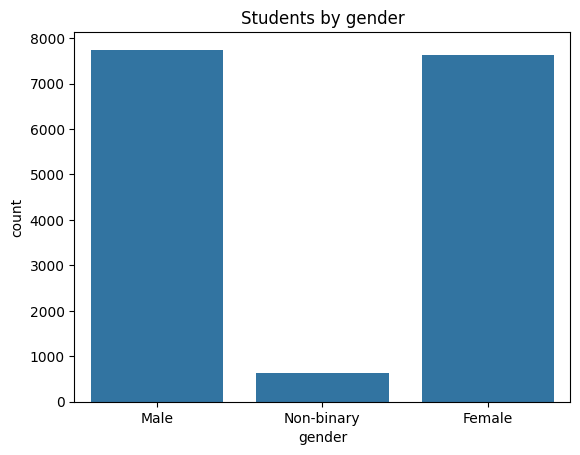

In [13]:
sns.countplot(data=df, x="gender")
plt.title("Students by gender")
plt.show()

In [14]:
df.groupby("gender")["mental_health_score"].mean().round(2)

,mental_health_score
gender,
Female,72.54
Male,72.48
Non-binary,72.12


## Students by Gender

Male and female students are almost evenly represented, at about 7,700 and 7,600 students each. Non-binary students make up a much smaller group of about 630 (roughly 4% of the dataset). Because that group is smaller, any comparison involving it should be read with a little more caution than comparisons between the two larger groups. Gender doesn't appear to matter much either.

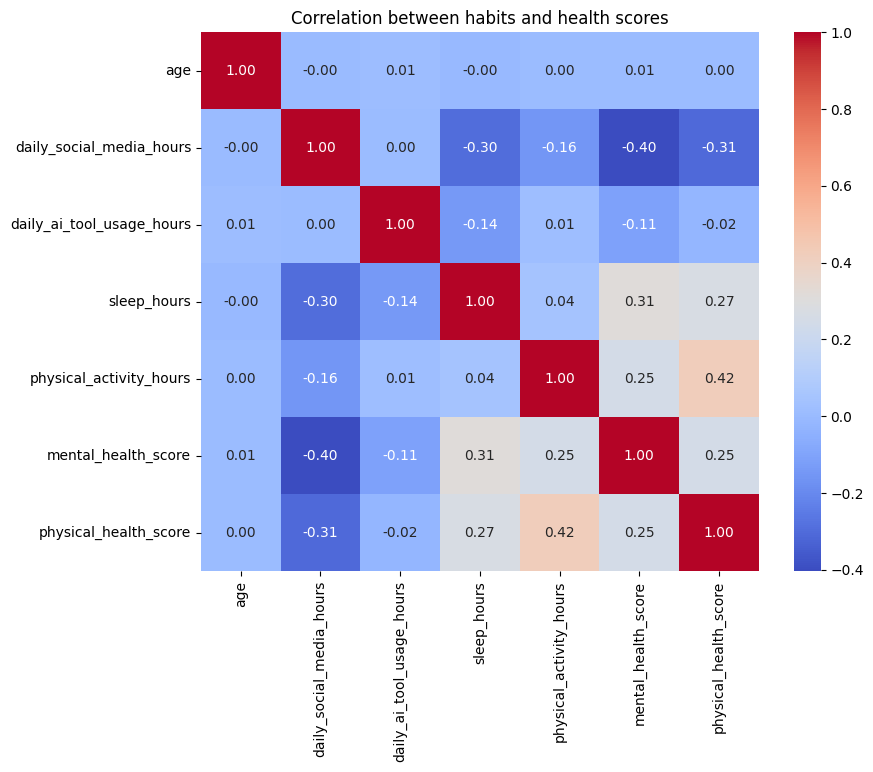

In [15]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between habits and health scores")
plt.savefig("heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Correlation Findings

- **Social media use has the strongest association with mental health score (r = -0.40):** students who spend more time on social media tend to have lower scores.
- **Sleep (r = +0.31) and physical activity (r = +0.25)** are positively associated with mental health score.
- **AI tool use is only weakly associated with mental health (r = -0.11)** and is essentially unrelated to physical health (r = -0.02).
- **Physical health score** is most strongly associated with physical activity (r = +0.42), followed by social media use (r = -0.31) and sleep (r = +0.27).
- **Social media use and sleep are negatively associated (r = -0.30),** so heavier social media users tend to sleep less. Part of the social media link to mental health may be connected to lost sleep, though correlation alone cannot confirm this.
- **Age has no meaningful association with any variable (all near 0),** consistent with the education level comparison.
- All relationships are moderate at most, and these are linear correlations only. They show association, not causation, and the data is synthetic.

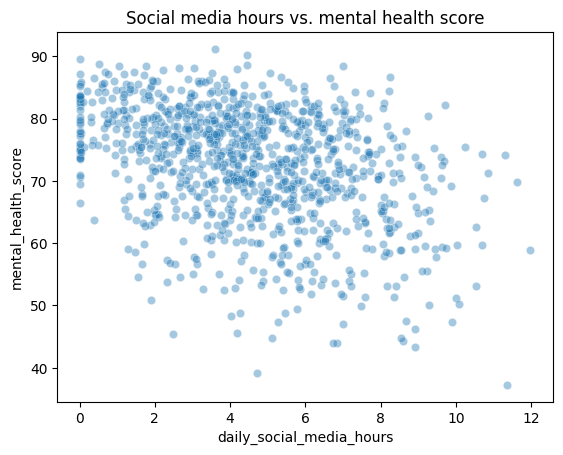

In [16]:
sns.scatterplot(data=df.sample(1000, random_state=42),
                x="daily_social_media_hours", y="mental_health_score", alpha=0.4)
plt.title("Social media hours vs. mental health score")
plt.show()

## Social Media Hours vs. Mental Health Score

The scatter plot shows a downward trend: students who use social media more tend to have lower mental health scores, consistent with the correlation of -0.40. The relationship is moderate, not tight, since scores at any given usage level vary widely. Students with no social media use rarely score below about 65, while very low scores (below 55) appear mostly among students who use it for several hours a day. This plot uses a random sample of 1,000 students for readability. It shows association, not causation.

In [17]:
level = pd.qcut(df["daily_social_media_hours"], 3, labels=["low", "medium", "high"])
df.groupby(level, observed=True)["mental_health_score"].mean().round(2)

,mental_health_score
daily_social_media_hours,
low,76.47
medium,72.75
high,68.22


In [18]:
ai_level = pd.qcut(df["daily_ai_tool_usage_hours"], 3, labels=["low", "medium", "high"], duplicates="drop")
df.groupby(ai_level, observed=True)["mental_health_score"].mean().round(2)

,mental_health_score
daily_ai_tool_usage_hours,
low,73.59
medium,72.52
high,71.36


## Group Comparisons

Students were split into three equal-sized groups (low, medium, high) based on their daily usage.

- **Social media:** average mental health scores fall steadily as usage rises, from 76.5 (low) to 72.8 (medium) to 68.2 (high). Heavy users score about 8 points lower than light users.
- **AI tools:** scores also decline with usage, from 73.6 (low) to 72.5 (medium) to 71.4 (high), but the gap is only about 2 points, much smaller than for social media.

This matches the correlation results: social media use has a moderate association with mental health score, while AI tool use has a weak one. These are associations in synthetic data, not evidence that either habit causes lower scores.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

target = "mental_health_score"
X = pd.get_dummies(df.drop(columns=[target, "physical_health_score"]), drop_first=True)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    print(name, "| R2:", round(r2_score(y_test, pred), 3),
          "| MAE:", round(mean_absolute_error(y_test, pred), 2))

Linear Regression | R2: 0.238 | MAE: 6.33
Random Forest | R2: 0.251 | MAE: 6.17


## Model Results

I predicted mental health score from age, gender, education level, social media hours, AI tool hours, sleep hours, and physical activity hours, using 80% of students for training and 20% for testing.

| Model | R2 | MAE |
|---|---|---|
| Linear Regression | 0.238 | 6.33 |
| Random Forest | 0.251 | 6.17 |

- Both models explain about a quarter of the variation in mental health scores, and predictions are off by about 6 points on average.
- The random forest is only slightly better than linear regression, which suggests the relationships are mostly linear and a more complex model adds little.
- The modest scores fit the moderate correlations seen earlier. Daily habits are associated with mental health, but most of the variation between students is not explained by the variables in this dataset.
- Because the data is synthetic, these scores describe how well the simulated patterns can be learned, not how well real student wellbeing could be predicted.

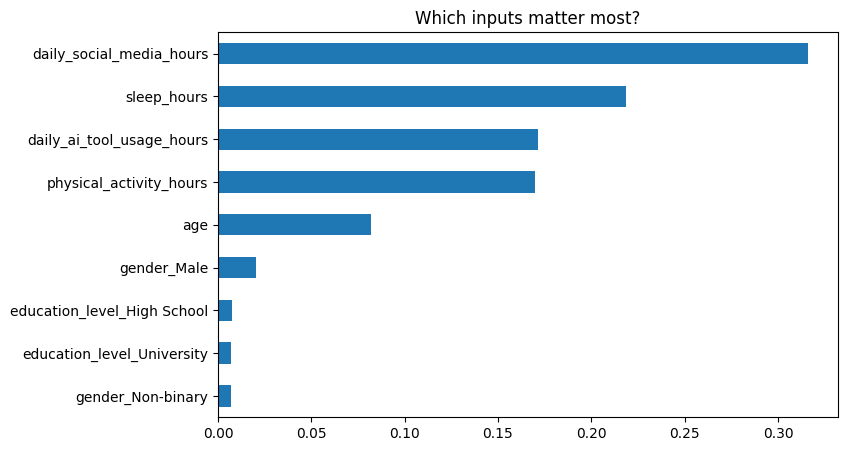

In [20]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", figsize=(8, 5))
plt.title("Which inputs matter most?")
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


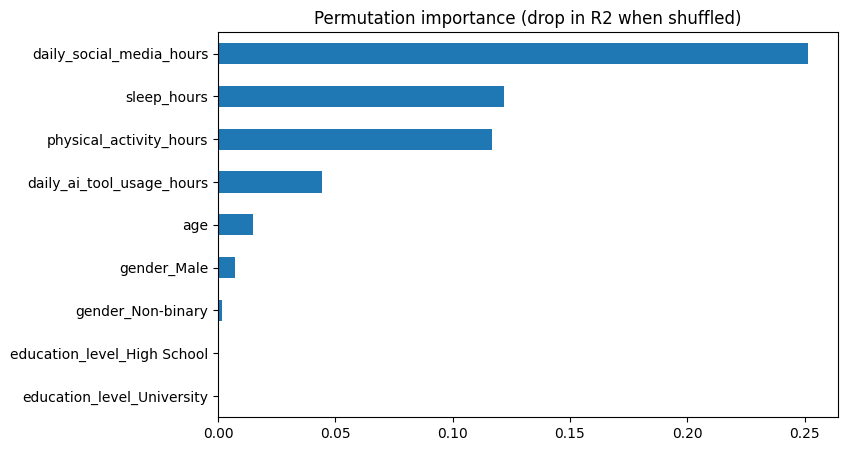

In [21]:
from sklearn.inspection import permutation_importance

result = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
perm = pd.Series(result.importances_mean, index=X.columns).sort_values()
perm.plot(kind="barh", figsize=(8, 5))
plt.title("Permutation importance (drop in R2 when shuffled)")
plt.savefig("permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## Feature Importance

I measured input importance two ways. The random forest's built-in importance ranked social media (0.32), sleep (0.22), AI tool use (0.17), and physical activity (0.17) as the top inputs. However, this method can overstate columns with many distinct values, so I checked it with permutation importance, which measures how much the model's accuracy drops when each input is shuffled.

The permutation results are more reliable and tell a clearer story:
- **Social media hours** has by far the largest effect.
- **Sleep and physical activity** come next, at about the same level.
- **AI tool use** has a small effect, much smaller than the built-in importance suggested.
- **Age, gender, and education level** contribute almost nothing.

This matches the correlation results. Importance shows what the model used to make predictions, not what causes mental health scores, and the data is synthetic.